In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [5]:
fact_sales = pd.read_csv('FACT_SALES (1).csv')
calendar = pd.read_excel('DIM_CALENDAR (2).xlsx')

In [6]:
print(fact_sales.head())
print(calendar.head())
print(fact_sales.columns)

    WEEK         ITEM_CODE  TOTAL_UNIT_SALES  TOTAL_VALUE_SALES  \
0  34-22  7501058792808BP2             0.006              0.139   
1  34-22     7501058715883             0.487            116.519   
2  34-22     7702626213774             1.391             68.453   
3  34-22     7501058716422             0.022              1.481   
4  34-22     7501058784353             2.037            182.839   

   TOTAL_UNIT_AVG_WEEKLY_SALES              REGION  
0                        1.000  TOTAL AUTOS AREA 5  
1                        2.916  TOTAL AUTOS AREA 5  
2                        5.171  TOTAL AUTOS AREA 5  
3                        1.833  TOTAL AUTOS AREA 5  
4                        5.375  TOTAL AUTOS AREA 5  
    WEEK  YEAR  MONTH  WEEK_NUMBER       DATE
0  01-21  2021      1            1 2021-01-10
1  02-21  2021      1            2 2021-01-17
2  03-21  2021      1            3 2021-01-24
3  04-21  2021      1            4 2021-01-31
4  05-21  2021      2            5 2021-02-07
Ind

In [7]:
df = fact_sales.merge(calendar, on='WEEK', how='left')

print(df.head())

    WEEK         ITEM_CODE  TOTAL_UNIT_SALES  TOTAL_VALUE_SALES  \
0  34-22  7501058792808BP2             0.006              0.139   
1  34-22     7501058715883             0.487            116.519   
2  34-22     7702626213774             1.391             68.453   
3  34-22     7501058716422             0.022              1.481   
4  34-22     7501058784353             2.037            182.839   

   TOTAL_UNIT_AVG_WEEKLY_SALES              REGION  YEAR  MONTH  WEEK_NUMBER  \
0                        1.000  TOTAL AUTOS AREA 5  2022      8           34   
1                        2.916  TOTAL AUTOS AREA 5  2022      8           34   
2                        5.171  TOTAL AUTOS AREA 5  2022      8           34   
3                        1.833  TOTAL AUTOS AREA 5  2022      8           34   
4                        5.375  TOTAL AUTOS AREA 5  2022      8           34   

        DATE  
0 2022-08-28  
1 2022-08-28  
2 2022-08-28  
3 2022-08-28  
4 2022-08-28  


In [8]:
features = df[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'REGION']]

# Convertir región a variables numéricas
features = pd.get_dummies(features, columns=['REGION'])

# Rellenar nulos
features = features.fillna(0)

print(features.head())

   TOTAL_UNIT_SALES  TOTAL_VALUE_SALES  REGION_TOTAL AUTOS AREA 1  \
0             0.006              0.139                      False   
1             0.487            116.519                      False   
2             1.391             68.453                      False   
3             0.022              1.481                      False   
4             2.037            182.839                      False   

   REGION_TOTAL AUTOS AREA 2  REGION_TOTAL AUTOS AREA 3  \
0                      False                      False   
1                      False                      False   
2                      False                      False   
3                      False                      False   
4                      False                      False   

   REGION_TOTAL AUTOS AREA 4  REGION_TOTAL AUTOS AREA 5  \
0                      False                       True   
1                      False                       True   
2                      False                       Tr

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

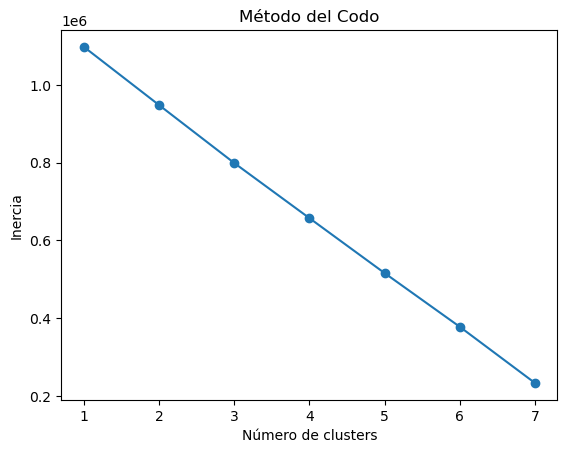

In [10]:
inertia = []
K = range(1, 8)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure()
plt.plot(K, inertia, marker='o')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')
plt.show()

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print(df[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'REGION', 'cluster']].head())

   TOTAL_UNIT_SALES  TOTAL_VALUE_SALES              REGION  cluster
0             0.006              0.139  TOTAL AUTOS AREA 5        0
1             0.487            116.519  TOTAL AUTOS AREA 5        0
2             1.391             68.453  TOTAL AUTOS AREA 5        0
3             0.022              1.481  TOTAL AUTOS AREA 5        0
4             2.037            182.839  TOTAL AUTOS AREA 5        0


In [12]:
cluster_analysis = df.groupby('cluster')[['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES']].mean()

print(cluster_analysis)

         TOTAL_UNIT_SALES  TOTAL_VALUE_SALES
cluster                                     
0                1.741539          50.384521
1               10.295853         281.635591
2                1.569838          48.718195


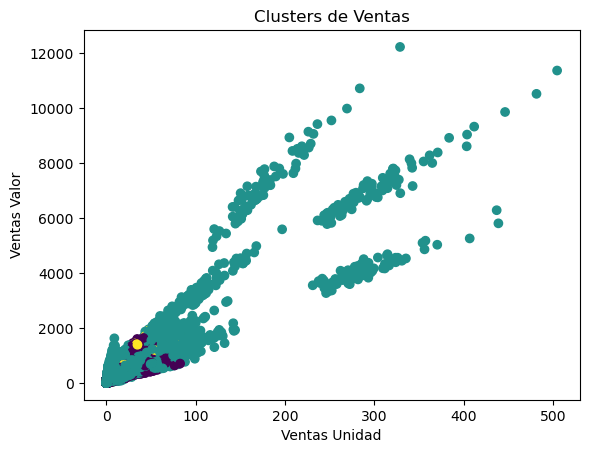

In [13]:
plt.figure()
plt.scatter(df['TOTAL_UNIT_SALES'], df['TOTAL_VALUE_SALES'], c=df['cluster'])
plt.xlabel('Ventas Unidad')
plt.ylabel('Ventas Valor')
plt.title('Clusters de Ventas')
plt.show()

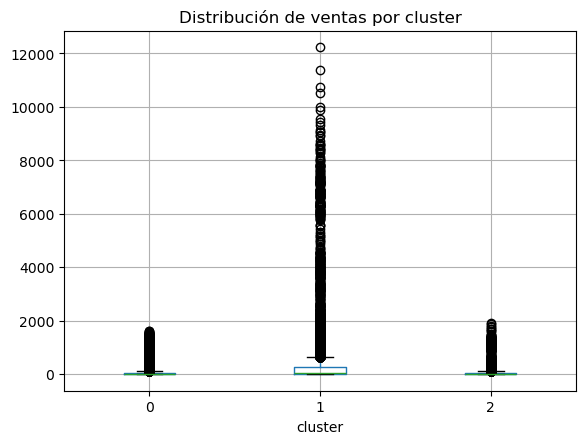

In [14]:
df.boxplot(column='TOTAL_VALUE_SALES', by='cluster')
plt.title('Distribución de ventas por cluster')
plt.suptitle('')
plt.show()

In [16]:
df.to_csv('resultados_clustering.csv', index=False)

## Análisis de resultados del clustering 

A partir de la aplicación del algoritmo K-Means, se identificaron tres clusters que agrupan productos/regiones con comportamientos similares en términos de ventas.

### Descripción de los clusters

- **Cluster 0 (Bajo desempeño):**
  Este grupo presenta bajos niveles tanto en ventas por unidad como en valor. Representa segmentos donde la marca Vanish tiene menor impacto o presencia en el mercado.

- **Cluster 1 (Desempeño medio):**
  Incluye productos o regiones con ventas moderadas. Este segmento es estable, pero tiene potencial de crecimiento si se optimizan estrategias comerciales.

- **Cluster 2 (Alto desempeño):**
  Este cluster agrupa los productos o regiones con mayores ventas. Representa los puntos fuertes de la marca y donde su estrategia está funcionando correctamente.

---

### Insights clave

- Existe una clara diferenciación entre segmentos de alto, medio y bajo desempeño.
- La marca Vanish tiene una concentración importante en el cluster de alto desempeño.
- Los clusters de bajo desempeño representan oportunidades estratégicas para mejorar ventas mediante promociones, distribución o posicionamiento.
- La región (variable incluida) influye en la agrupación, lo que sugiere diferencias geográficas en el comportamiento del mercado.

---

### Implicaciones estratégicas

- Se recomienda enfocar recursos en potenciar los clusters de alto desempeño.
- Diseñar estrategias específicas para los clusters de bajo rendimiento.
- Analizar más a fondo las regiones con menor desempeño para detectar barreras de mercado.

---

### Conclusión

El uso de clustering permitió segmentar eficazmente el mercado en grupos diferenciados, facilitando la identificación de oportunidades de mejora y optimización de la estrategia comercial de la marca Vanish.